# Clustering II: shapes k-means cannot find
## Where were the campus e-scooters left?
**Salem Othman · Student notebook**

On Wednesday k-means grouped café customers well, because those groups were round blobs. Today's data is different: the GPS position of 335 shared e-scooters, left around campus last week. Scooters pile up along a curved river path, in a ring around the plaza fountain, by the fountain itself, outside the dorms, and a few are dumped anywhere.

You will see k-means fail on these shapes, then learn two methods that handle them: **hierarchical clustering** (build a tree of joins, then cut it) and **DBSCAN** (follow crowded areas, and call lonely points noise). The last part is an audit of an AI that picks the wrong method using a real number.

### Today's five steps
| Part | Step | What you do | Exercise |
|---|---|---|---|
| 1 | k-means fails | Run k-means on the scooter map and see what it cuts | E1 |
| 2 | Hierarchical | Build a tree of joins, cut it, try two ways of joining | E2 |
| 3 | DBSCAN | Find crowded areas and noise | E3 |
| 4 | Choose eps | Try five circle sizes and pick one | E4 |
| 5 | Compare | Put the methods side by side, then audit an AI | E5 |

**For every exercise:** predict → write the code → check → explain.

**How to work**
- Run cells from top to bottom with **Shift + Enter**.
- In an exercise cell, **write the code yourself** under each numbered step. Keep the variable names exactly as written; the Check cell looks for them.
- `PASS` means that step is done. `FIX` tells you what to look at.
- If a Check cell says an exercise **is not finished yet**, that is not an error: write the code in the exercise cell above, run it, then run the Check cell again.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
RANDOM_STATE = 42

# Five colours and five marker shapes, so groups can be told apart even in grayscale.
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cc2"]
CLUSTER_MARKERS = ["o", "s", "^", "D", "P"]


def plot_clusters(ax, points, labels, title):
    """Draw the scooter map coloured by cluster. Label -1 (noise) is drawn as a black x."""
    labels = np.asarray(labels)
    for j in sorted(set(labels) - {-1}):
        mask = labels == j
        tiny = mask.sum() <= 3            # a cluster of one or two scooters: draw it big so you can see it
        ax.scatter(points["east_m"][mask], points["north_m"][mask],
                   s=110 if tiny else 20, color=CLUSTER_COLORS[j % 5], marker=CLUSTER_MARKERS[j % 5],
                   alpha=0.85, edgecolor="#22303c" if tiny else "white", linewidth=1.5 if tiny else 0.4)
    noise = labels == -1
    if noise.any():
        ax.scatter(points["east_m"][noise], points["north_m"][noise], s=40, color="#22303c",
                   marker="x", linewidth=1.5, label="noise (-1)")
        ax.legend(frameon=False, loc="upper left")
    ax.set_title(title)
    ax.set_xlabel("metres east of the main gate")
    ax.set_ylabel("metres north")
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)


def check(label, passed):
    """Print PASS or FIX for one requirement."""
    print(("PASS  " if passed else "FIX   ") + label)

def ready(value, step):
    """True when the exercise above is done. Otherwise print a reminder and return False.

    It never raises, so a blank exercise cell can never stop the class with a red
    traceback: the Check cell just tells the student what to do next.
    """
    if value is None:
        print(f"{step} is not finished yet.")
        print("Write your code in the exercise cell above, run that cell, then run this one again.")
        return False
    return True

print("Setup complete.")

Setup complete.


# Part 0 · The scooters
Each row is one shared e-scooter, at the spot where its last rider left it.

| Column | Meaning |
|---|---|
| `scooter_id` | The scooter's number. Useful for tracing a row, never a clustering input. |
| `east_m` | Metres east of the campus main gate |
| `north_m` | Metres north of the campus main gate |

The scooter company wants to know **where scooters gather**, so it can put parking racks there and send a van to collect the stray ones. There is no answer column: nobody marked which "place" each scooter belongs to.

Scooters: 335


,scooter_id,east_m,north_m
0,S001,350.5,229.7
1,S002,317.3,243.4
2,S003,100.3,106.2
3,S004,259.1,147.8
4,S005,73.2,78.5


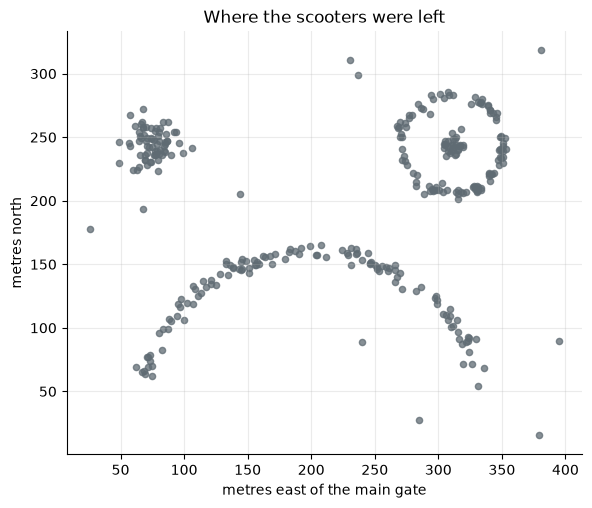

In [2]:
rng = np.random.default_rng(16)

# Where shared e-scooters were left on campus last week, in metres east and north of the main gate.
# Students leave them in four places, and a few are dumped anywhere.
angle = rng.uniform(0.1 * np.pi, 0.9 * np.pi, 120)                 # the river path: a long curved strip
river_path = np.c_[200 + 140 * np.cos(angle), 20 + 140 * np.sin(angle)] + rng.normal(0, 4, (120, 2))

angle = rng.uniform(0, 2 * np.pi, 100)                             # the plaza: a ring around the fountain
plaza_ring = np.c_[310 + 40 * np.cos(angle), 245 + 40 * np.sin(angle)] + rng.normal(0, 2.5, (100, 2))

fountain = rng.normal([310, 245], 5, (30, 2))                      # by the fountain, inside the ring
dorms = rng.normal([75, 245], 11, (70, 2))                         # outside the dorms: one round crowd
dumped = np.c_[rng.uniform(0, 400, 15), rng.uniform(0, 320, 15)]   # left anywhere

points = np.vstack([river_path, plaza_ring, fountain, dorms, dumped]).round(1)
scooters = (pd.DataFrame(points, columns=["east_m", "north_m"])
              .sample(frac=1, random_state=2).reset_index(drop=True))
scooters.insert(0, "scooter_id", [f"S{i:03d}" for i in range(1, len(scooters) + 1)])

print("Scooters:", len(scooters))
display(scooters.head())

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(scooters["east_m"], scooters["north_m"], s=20, color="#5f6b73", alpha=0.75)
ax.set_title("Where the scooters were left")
ax.set_xlabel("metres east of the main gate")
ax.set_ylabel("metres north")
ax.set_aspect("equal")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Write:** look at the map. How many places do scooters gather? Describe each one's shape in a few words (round, curved, ring...).

*Your answer:*
Scooters gather in 3 distinct places. The first is a cluster, second is a curved line, the third is a ring with a cluster in the center.

# Part 1 · k-means on the scooter map
Wednesday's k-means puts each point with its **nearest centre**. Two things follow from that:
1. Every group is **round-ish**: a centre and everything near it.
2. **Every point** joins some group, even a scooter dumped far from everything.

**No scaling today.** Both columns are metres on the same map, so a metre east and a metre north already count the same. Scaling would stretch the map and bend the shapes.

### E1 · k-means with k = 4
**Predict:** there are four places on the map. Will k-means with k = 4 find them?
Yes, it will find 4 of them

In [3]:
X = None
kmeans_labels = None
kmeans_sizes = None

# Write your code below. Your code must create the variables set to None above.

# 1. X: the two position columns of scooters (not scooter_id). Do not scale.
#    Hint: scooters[["east_m", "north_m"]]
X = scooters[["east_m", "north_m"]]

# 2. kmeans_labels: the cluster of every scooter, from
#    KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
#    Hint: .fit_predict(X) fits and returns the labels in one step.
kmeans_labels = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(X)

# 3. kmeans_sizes: how many scooters are in each cluster. Display it.
#    Hint: pd.Series(kmeans_labels).value_counts().sort_index()
kmeans_sizes = pd.Series(kmeans_labels).value_counts().sort_index()

display(kmeans_sizes)

0    135
1     72
2     60
3     68
Name: count, dtype: int64

**Check E1**

In [4]:
if ready(X, "E1") and ready(kmeans_labels, "E1") and ready(kmeans_sizes, "E1"):
    check("X holds east_m and north_m only", list(X.columns) == ["east_m", "north_m"])
    check("X is still in metres (not scaled)", X["east_m"].max() > 100)
    check("every scooter has a k-means label", len(kmeans_labels) == len(scooters))
    check("k-means made 4 clusters", len(set(kmeans_labels)) == 4)
    check("kmeans_sizes adds up to every scooter", kmeans_sizes.sum() == len(scooters))

PASS  X holds east_m and north_m only
PASS  X is still in metres (not scaled)
PASS  every scooter has a k-means label
PASS  k-means made 4 clusters
PASS  kmeans_sizes adds up to every scooter


### Worked example · Look at what k-means did

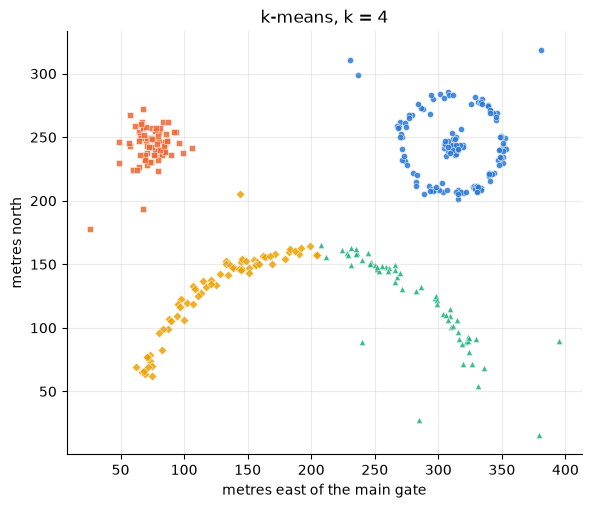

In [5]:
if ready(kmeans_labels, "E1"):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    plot_clusters(ax, X, kmeans_labels, "k-means, k = 4")
    plt.show()

**Write:** which places did k-means get right? Which did it cut in pieces or mix together? Why does k-means do that?

*Your answer:*
KMeans got the group and the ring, but it split the curve into 2 clusters

# Part 2 · Hierarchical clustering
**Hierarchical clustering** never picks centres. It works bottom-up:

1. Start with every point as its own cluster.
2. Find the two **closest** clusters.
3. Join them. In the tree, draw the join at the height of that distance.
4. Repeat until one cluster is left.
5. **Cut the tree** with a horizontal line: each branch the line crosses is one cluster.

The tree is called a **dendrogram**. You don't choose the number of clusters until you cut it.

**"Closest" between two groups** can mean different things. This choice is called the **linkage**:

| Linkage | Distance between two groups | Behaves like |
|---|---|---|
| `single` | The **closest pair** of points, one from each group | Follows chains of points, so it can follow curves. Also chains through stray points. |
| `ward` | How much the spread grows if the two groups are joined | k-means: round groups of similar size |

Here are the 6 points from the slides. The worked cell below draws their tree.

In [6]:
toy = pd.DataFrame({
    "point": list("ABCDEF"),
    "x": [1, 2, 6, 6, 2, 9],
    "y": [1, 1, 5, 6.5, 3.2, 6],
})
toy_xy = toy[["x", "y"]]
display(toy)

,point,x,y
0,A,1,1.0
1,B,2,1.0
2,C,6,5.0
3,D,6,6.5
4,E,2,3.2
5,F,9,6.0


### E2 · Build a tree, then cluster the scooters two ways
**Predict:** single linkage joins the closest pair at every step. On the scooter map, what could go wrong with the stray scooters?

`linkage()` returns one row per join. Each row is: the two clusters joined, the distance (height) of the join, and how many points the new cluster has. Points are numbered 0–5 (A–F); the cluster made by the first join is number 6, the next is 7, and so on.

Single linkage could cause clusters to be isolated from actual clusters.

In [7]:
merges = None
ward_labels = None
single_labels = None

# Write your code below. Your code must create the variables set to None above.

# 1. merges: the joins for the 6 toy points, using single linkage.
#    Hint: linkage(toy_xy, method="single")
#    Display it as a table:
#    pd.DataFrame(merges, columns=["cluster_a", "cluster_b", "height", "size"])
merges = linkage(toy_xy, method="single")

display(pd.DataFrame(merges, columns=["cluster_a", "cluster_b", "height", "size"]))
# 2. ward_labels: 4 clusters of the scooters (X) with Ward linkage.
#    Hint: AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X)
ward_labels = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X)
# 3. single_labels: the same with linkage="single".
single_labels = AgglomerativeClustering(n_clusters=4, linkage="single").fit_predict(X)
# 4. Print the size of each cluster for both.
#    Hint: pd.Series(ward_labels).value_counts()
print("Ward:\n", pd.Series(ward_labels).value_counts().tolist())
print("Single:\n", pd.Series(single_labels).value_counts().tolist())

,cluster_a,cluster_b,height,size
0,0.0,1.0,1.000000,2.0
1,2.0,3.0,1.500000,2.0
2,4.0,6.0,2.200000,3.0
3,5.0,7.0,3.041381,3.0
4,8.0,9.0,4.386342,6.0


Ward:
 [135, 72, 70, 58]
Single:
 [198, 135, 1, 1]


**Check E2**

In [8]:
if ready(merges, "E2") and ready(ward_labels, "E2") and ready(single_labels, "E2"):
    check("merges has one row per join (6 points need 5 joins)", np.shape(merges) == (5, 4))
    check("the first join is the closest pair of points", np.isclose(merges[0, 2], pdist(toy_xy).min()))
    check("join heights never go down", bool(np.all(np.diff(merges[:, 2]) >= 0)))
    check("the last join holds all 6 points", merges[-1, 3] == 6)
    check("Ward gave every scooter one of 4 clusters", len(ward_labels) == len(X) and len(set(ward_labels)) == 4)
    check("single linkage gave every scooter one of 4 clusters", len(single_labels) == len(X) and len(set(single_labels)) == 4)
    check("the two linkages give different clusters", not np.array_equal(np.sort(np.bincount(ward_labels)),
                                                                        np.sort(np.bincount(single_labels))))

PASS  merges has one row per join (6 points need 5 joins)
PASS  the first join is the closest pair of points
PASS  join heights never go down
PASS  the last join holds all 6 points
PASS  Ward gave every scooter one of 4 clusters
PASS  single linkage gave every scooter one of 4 clusters
PASS  the two linkages give different clusters


### Worked example · The tree, and cutting it
`fcluster(merges, t=..., criterion="distance")` cuts the tree at height `t`: every join above the line is undone.

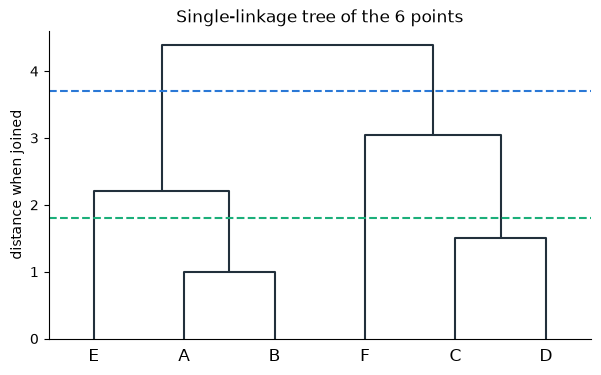

cut at 3.7: {'A': 1, 'B': 1, 'C': 2, 'D': 2, 'E': 1, 'F': 2}
cut at 1.8: {'A': 1, 'B': 1, 'C': 3, 'D': 3, 'E': 2, 'F': 4}


In [9]:
if ready(merges, "E2"):
    fig, ax = plt.subplots(figsize=(7, 4))
    dendrogram(merges, labels=toy["point"].tolist(), ax=ax, color_threshold=0, above_threshold_color="#22303c")
    for height, colour in [(3.7, "#2a78d6"), (1.8, "#1baf7a")]:
        ax.axhline(height, color=colour, linestyle="--")
    ax.set_ylabel("distance when joined")
    ax.set_title("Single-linkage tree of the 6 points")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

    for height in [3.7, 1.8]:
        groups = fcluster(merges, t=height, criterion="distance")
        print(f"cut at {height}:", dict(zip(toy["point"], groups.tolist())))

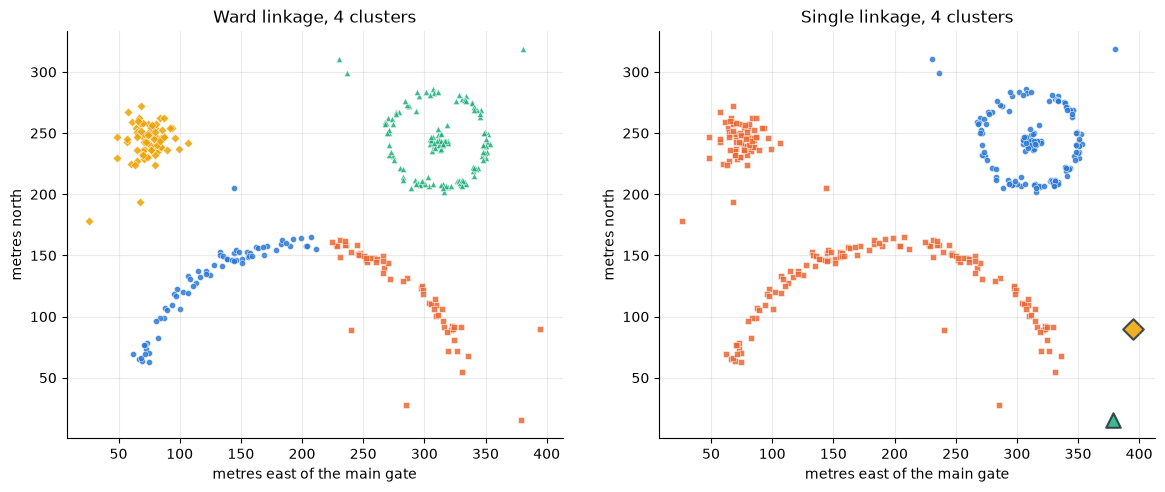

In [10]:
if ready(ward_labels, "E2") and ready(single_labels, "E2"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    plot_clusters(axes[0], X, ward_labels, "Ward linkage, 4 clusters")
    plot_clusters(axes[1], X, single_labels, "Single linkage, 4 clusters")
    plt.tight_layout()
    plt.show()

**Write:** (a) Which linkage looks like k-means? (b) What did single linkage do with its 4 clusters, and why? Use the cluster sizes.

*Your answer:*
Ward linkage looks the most like k-means, there are 4 clusters that appear the same as k-means. 
Single linkage produced one giant cluster, and three tiny clusters/outliers. 

# Part 3 · DBSCAN: follow the crowds
**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) has two settings:

- `eps`: the radius of a circle drawn around each point, in the data's units (here metres).
- `min_samples`: how many points must be inside a point's circle, **the point itself included**, for it to count as crowded.

Then every point is one of three kinds:

| Kind | Rule | What happens |
|---|---|---|
| **Core** | Its circle holds at least `min_samples` points | Starts or grows a cluster |
| **Border** | Not core, but inside a core point's circle | Joins that cluster, doesn't grow it |
| **Noise** | Not core, and in no core point's circle | Gets the label **-1** |

You never give the number of clusters: it comes out of the data. A cluster can be any shape, as long as it is crowded all the way along.

### E3 · DBSCAN on the scooters
**Predict:** with circles of 15 m and at least 5 scooters per circle, how many clusters will DBSCAN find? Will the ring and the fountain be separate?
It will find 4 clusters

In [11]:
db_labels = None
n_clusters = None
n_noise = None

# Write your code below. Your code must create the variables set to None above.

# 1. db_labels: the cluster of every scooter from DBSCAN(eps=15, min_samples=5), fitted on X.
#    Hint: DBSCAN(eps=15, min_samples=5).fit_predict(X)
db_labels = DBSCAN(eps=15, min_samples=5).fit_predict(X)

# 2. n_clusters: the number of clusters. -1 is NOT a cluster, so leave it out.
#    Hint: len(set(db_labels) - {-1})
n_clusters = len(set(db_labels) - {-1})

# 3. n_noise: how many scooters got the label -1.
#    Hint: int((db_labels == -1).sum())
n_noise = int((db_labels == -1).sum())

# 4. Print n_clusters, n_noise and the size of each cluster.
print(f"n_clusters: {n_clusters}\nn_noise: {n_noise}\nsize: {db_labels.size}")

n_clusters: 4
n_noise: 12
size: 335


**Check E3**

In [12]:
if ready(db_labels, "E3") and ready(n_clusters, "E3") and ready(n_noise, "E3"):
    expected = DBSCAN(eps=15, min_samples=5).fit_predict(X)
    check("db_labels has one label per scooter", len(db_labels) == len(X))
    check("db_labels comes from DBSCAN with eps=15 and min_samples=5", np.array_equal(db_labels, expected))
    check("n_clusters leaves out the noise label -1", n_clusters == len(set(db_labels) - {-1}))
    check("n_noise counts the -1 labels", n_noise == int((db_labels == -1).sum()))

PASS  db_labels has one label per scooter
PASS  db_labels comes from DBSCAN with eps=15 and min_samples=5
PASS  n_clusters leaves out the noise label -1
PASS  n_noise counts the -1 labels


### Worked example · DBSCAN's map

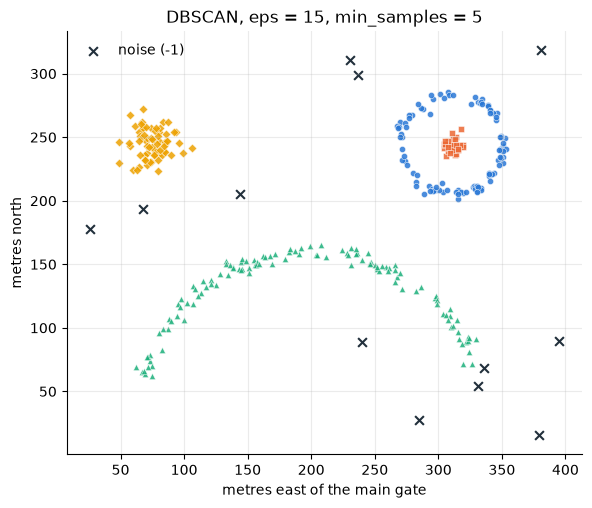

In [13]:
if ready(db_labels, "E3"):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    plot_clusters(ax, X, db_labels, "DBSCAN, eps = 15, min_samples = 5")
    plt.show()

**Write:** (a) Which places did DBSCAN find? (b) Where are the noise scooters on the map, and what should the company do about them?

*Your answer:*
(a): DBSCAN found a circle, a circle inside a ring, and a curve. 
(b): The noise scooters are gathered at the edge of a cluster. They should ignore the noise. 

# Part 4 · Choosing eps
`eps` decides what "close" means:
- **Too small:** circles are tiny, few points are core. Real places break into pieces, and many scooters become noise.
- **Too large:** circles reach across gaps. Separate places merge.

A good sign is a **range** of eps values that all give the same answer: then the answer does not depend on a lucky setting.

### E4 · Try five circle sizes
**Predict:** at the largest eps, 30 m, will the ring and the fountain still be separate clusters?
No, they will be the same cluster. 

In [14]:
eps_table = None
chosen_eps = None

eps_values = [5, 10, 15, 20, 30]

# Write your code below. Your code must create the variables set to None above.

# 1. For every eps in eps_values, run DBSCAN(eps=eps, min_samples=5) on X and collect:
#    eps, clusters (leave out -1), noise (how many -1 labels).
rows = []
for eps in eps_values:
    e = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    rows.append(
        {
            "eps": eps,
            "clusters": len(set(e) - {-1}),
            "noise": int((e == -1).sum()),
        }
    )

# 2. eps_table: those rows as a DataFrame. Display it.
eps_table = pd.DataFrame(rows)
display(eps_table)
# 3. chosen_eps: the eps you would use. Choose it yourself from the table and the
#    pictures below, then explain your choice in the answer cell.
chosen_eps = 20

,eps,clusters,noise
0,5,16,157
1,10,11,19
2,15,4,12
3,20,4,10
4,30,3,10


**Check E4**

In [15]:
if ready(eps_table, "E4") and ready(chosen_eps, "E4"):
    check("eps_table has one row per eps", len(eps_table) == len(eps_values))
    check("eps_table reports eps, clusters and noise", set(eps_table.columns) >= {"eps", "clusters", "noise"})
    check("the cluster counts leave out -1",
          all(row.clusters == len(set(DBSCAN(eps=row.eps, min_samples=5).fit_predict(X)) - {-1})
              for row in eps_table.itertuples()))
    check("noise never goes up as the circles get bigger", eps_table["noise"].is_monotonic_decreasing)
    check("chosen_eps is one of the values you tried", chosen_eps in eps_values)

PASS  eps_table has one row per eps
PASS  eps_table reports eps, clusters and noise
PASS  the cluster counts leave out -1
PASS  noise never goes up as the circles get bigger
PASS  chosen_eps is one of the values you tried


### Worked example · All five maps

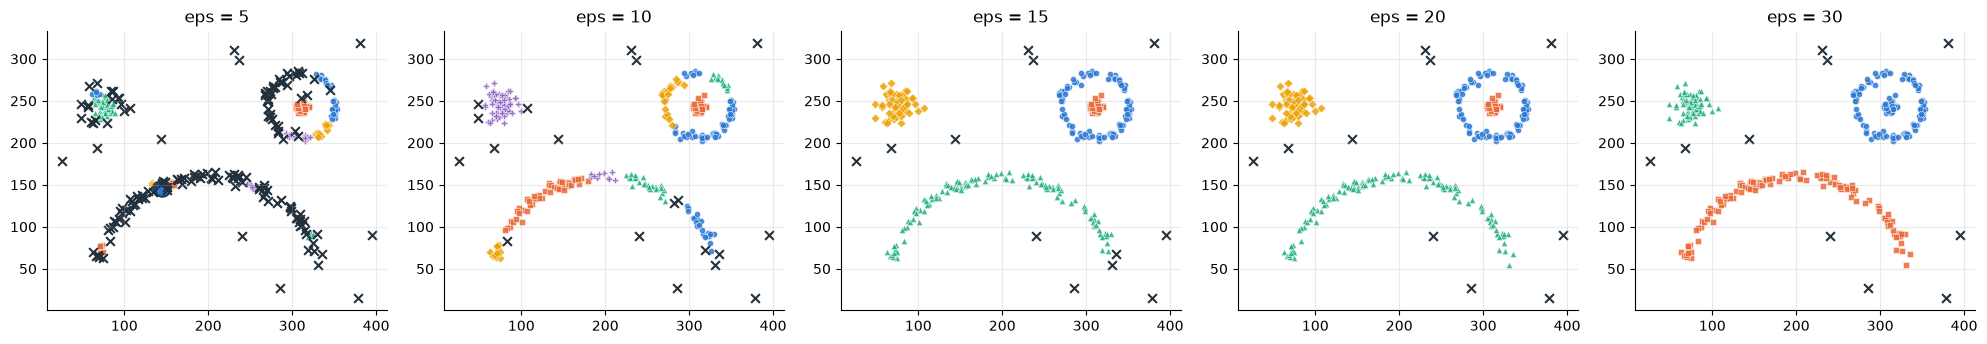

In [16]:
if ready(eps_table, "E4"):
    fig, axes = plt.subplots(1, len(eps_values), figsize=(20, 4.2))
    for ax, eps in zip(axes, eps_values):
        labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
        plot_clusters(ax, X, labels, f"eps = {eps}")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if ax.get_legend():
            ax.get_legend().remove()
    plt.tight_layout()
    plt.show()

**Write:** which eps did you choose? Say what goes wrong at the smallest and at the largest eps, using the table.

*Your answer:*
I chose eps 20, 
at eps 5: there are too many clusters and a significant amount of noise. 
at eps 30: It fails to differentiate the ring and the circle inside of the ring. 

# Part 5 · Compare the methods, then audit the AI
Wednesday you judged k-means with **silhouette**: for each point, how much closer it is to its own group than to the next group. Today, check whether silhouette agrees with your eyes.

For DBSCAN, compute silhouette on the **non-noise** scooters only: -1 is not a group, so it has no "own group" to be close to.

### E5 · One table, four methods
**Predict:** which method will get the highest silhouette? Which one matched the map best?
ward will get the highest silhouette


In [17]:
compare = None

methods = None
if ready(kmeans_labels, "E1") and ready(ward_labels, "E2") and ready(db_labels, "E3"):
    methods = {
        "k-means": kmeans_labels,
        "Ward": ward_labels,
        "single linkage": single_labels,
        "DBSCAN": db_labels,
    }

# Write your code below. Your code must create the variables set to None above.

# 1. For each name, labels in methods.items(), collect:
#    method, clusters (leave out -1), noise (how many -1), silhouette.
#    Compute silhouette on the non-noise scooters only:
#    Hint: keep = labels != -1
#    Hint: silhouette_score(X[keep], labels[keep])
rows = []
for name, labels in methods.items():
    keep = labels != -1
    rows.append(
        {
            "method": name,
            "clusters": len(set(labels) - {-1}),
            "noise": int((labels == -1).sum()),
            "keep": keep,
            "silhouette": silhouette_score(X[keep], labels[keep]),
        }
    )


# 2. compare: those rows as a DataFrame. Display it, rounded to 3 decimals.
compare = pd.DataFrame(rows)

display(compare.round(3))

,method,clusters,noise,keep,silhouette
0,k-means,4,0,"[True, True, True, True, True, True, True, Tru...",0.638
1,Ward,4,0,"[True, True, True, True, True, True, True, Tru...",0.638
2,single linkage,4,0,"[True, True, True, True, True, True, True, Tru...",0.436
3,DBSCAN,4,12,"[True, True, True, True, True, True, True, Tru...",0.277


**Check E5**

In [18]:
if ready(compare, "E5"):
    check("compare has one row per method", len(compare) == len(methods))
    check("compare reports method, clusters, noise and silhouette",
          set(compare.columns) >= {"method", "clusters", "noise", "silhouette"})
    check("every silhouette is between -1 and 1", compare["silhouette"].between(-1, 1).all())
    check("k-means and the tree methods have no noise",
          (compare.loc[compare["method"] != "DBSCAN", "noise"] == 0).all())
    check("DBSCAN's noise matches E3", compare.loc[compare["method"] == "DBSCAN", "noise"].iloc[0] == n_noise)

PASS  compare has one row per method
PASS  compare reports method, clusters, noise and silhouette
PASS  every silhouette is between -1 and 1
PASS  k-means and the tree methods have no noise
PASS  DBSCAN's noise matches E3


**Write:** which method has the highest silhouette? Which one matched the four places on the map? Why do the two answers disagree?

*Your answer:*
k-means and ward had the highest silhouette, ward matched the 4 places on the map while k-means found different clusters. 

### The AI's analysis
The scooter company pastes this table into an AI assistant. It replies:

> "k-means is clearly the best method for your data: its silhouette is 0.638, while DBSCAN only reaches 0.277, so the k-means groups are more than twice as good. DBSCAN also gave 12 scooters the label -1; those rows are errors, so delete them before you report. And if you want k-means to follow the curved river path, just run it with `n_init=100` so it tries harder."

Each claim can be checked. You may write code in the cell below to test the last one.

In [19]:
# Optional: test the AI's last claim here.

**Write:** find **three** problems in the AI's answer. For each one, give the evidence from your notebook.

*Your answer:*
1. Silhouette evaluated spherical clusters, it penalizes curved paths. 
2. Label -1 are not errors to be removed. 
3. Running more inits will never allow it to find curves. 

### Challenge tasks (optional)
1. Run DBSCAN with `eps=15` and `min_samples=3`, then `min_samples=10`. What changes in the number of clusters and noise? Why?
2. Scale X with `StandardScaler` and run `DBSCAN(eps=15, min_samples=5)` on it. What happens, and what eps would you need instead?
3. Run `AgglomerativeClustering(n_clusters=6, linkage="single")`. Do the extra clusters find a new place, or more single stray scooters?

# Exit ticket
Answer without running more code.
1. In DBSCAN, what do `eps` and `min_samples` mean? What does the label -1 mean?
2. Why did k-means cut the river path into two pieces?
3. k-means had a higher silhouette than DBSCAN. Why does that not make k-means the right choice for the scooter map?

*Your answers:*
1. eps is the maximum distance to search for neighbors, min_samples is the minimum number of points in eps. 
2. k-means does not follow non-linear shapes
3. Sihlouette score favors spherical shapes, this rewards k-means and penalizes DBSCAN

# Submit
- Restart the kernel and run all cells. Every check should print `PASS`.
- Every *Your answer* and *Your prediction* cell is filled in.
- Submit this notebook with its outputs.